# Task 1: Data Preprocessing

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

In [ ]:
#1) Read the data from your individual variant into the Python notebook.
data = pd.read_excel("10_Student_Performance.xlsx")

In [ ]:
#2) Output the main information (number of variables, number of instances).
data.info()
data.shape

In [ ]:
#3) Output several first rows of the dataset.
data.head()

In [ ]:
#4) Make explanatory data analyses for each variable (mean, std, etc.).
data.describe(include='all')

In [ ]:
#5) Look at the independent and dependent variables. Divide the dataset accordingly into matrices X and Y.
# Output the shapes of these matrices.
# => We will convert the 'G3' from a numerical to binary 'pass/fail' (pass when G3 >= 10 and fail when G3 < 10)

data['Class'] = np.where(data.G3 >= 10, 'Pass', 'Fail')
Y = data.Class
X = data.drop(['Class', 'G3'], axis=1)

print("X shape:", X.shape)
print("Y shape:", Y.shape)
print("Number of unique classes:", Y.nunique())
Y.value_counts()

In [ ]:
# 6) Look at data types of the variables. Are there any categorical variable you need to encode? Execute
# necessary transformations. Drop some columns if necessary, when recommended in your individual
# variant or the variables are not suitable for the prediction (e.g., Ids, person names).

# => we can easily encode the binary variables such as 'school', 'sex', 'adress' and so on, 
# and also the nominal variables, and we created 2 new variables from G1 and G2 that represent
# the average and the change between the two then we dropped them to avoid multicollinearity.

X['G_Avg'] = (X.G1 + X.G2) / 2
X['Grade_Change'] = X.G2 - X.G1
X = X.drop(['G1','G2'], axis=1)
le = LabelEncoder()
Y_encoded = le.fit_transform(Y)

X_encoded = pd.get_dummies(X,drop_first=True, dtype=int)
X_encoded.info()

In [ ]:
# 7) Are there any Nan values? Try different filling of them (mean, median).
X_encoded.isnull().sum().sum()

In [ ]:
# 8) Check the dependences between each of the independent variable and the target variable and among
# the independent variables. Output correlation table and corresponding heatmap results.

corr_data = X_encoded.copy()
corr_data['Target_Class'] = Y_encoded

corr_table = corr_data.corr()
display(corr_table)
plt.figure(figsize=(20, 15))
sns.heatmap(corr_table, annot=False, cmap='coolwarm')
plt.show()

In [ ]:
#9) Build 2D plots of dependences between each pair of the variables. Which conclusion can you make?
list_variables = corr_table['Target_Class'].abs().nlargest(6).index
sns.pairplot(corr_data[list_variables], hue='Target_Class')
plt.show()

In [ ]:
# Conclusions : 
# - G_Avg is the strongest separator between classes, with failing students (class 0) concentrated 
# below 10 and passing students (class 1) above 10.
# - Students with higher studytime and plans for higher education (higher_yes = 1) achieve higher 
# G_Avg scores and predominantly pass, while students with multiple past failures cluster at lower G_Avg values and fail.

# Task 2: Data Analysis

In [ ]:
# 1) Divide your dataset into 2 parts: training set and testing set (80:20). Use some specific random_state to
# be capable to repeat the used split of the data. Output the dimension of the resulting datasets.

X_train, X_test, Y_train, Y_test = train_test_split(
    X_encoded, Y_encoded, test_size=0.2, random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("Y_train shape:", Y_train.shape)
print("Y_test shape:", Y_test.shape)


In [ ]:
# 2) Scale your datasets with MinMax Scaler.

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# 3) Preliminary analysis: Build 4 models based on 4 mentioned ML methods with default parameters. For
# each model: train with training set and output the regression score (R2), MSE, MAE of the model using
# training set. Now test your model with a testset and output the regression score (R2) and other metrics.
# Compare the metrics obtained with training and testset. Output dataframes with the following
# information. One dataframe for each metrics (e.g. 3 dataframes). Each row of the dataframe should
# correspond to a model and two columns correspond to the metric calculated on the training set and on
# the testset. Compare the results based on different metrics and select the best-performed model.
# Construct prediction squared errors histograms for each of the models, construct parity plots of each
# model.

models = {'Logistic Regression': LogisticRegression(), 
          'Decision Tree': DecisionTreeClassifier(random_state=42),
          'SVM': SVC(),
          'KNN': KNeighborsClassifier()}

accuracy_results = {}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, (name, model) in enumerate(models.items()):
    model.fit(X_train_scaled, Y_train)

    train_pred = model.predict(X_train_scaled)
    test_pred = model.predict(X_test_scaled)

    train_acc = accuracy_score(Y_train, train_pred)
    test_acc = accuracy_score(Y_test, test_pred)

    accuracy_results[name] = {
        'Train Accuracy': train_acc,
        'Test Accuracy': test_acc
    }

    cm = confusion_matrix(Y_test, test_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Fail (0)', 'Pass (1)'])
    disp.plot(ax=axes[i], cmap='Blues', colorbar=False)
    axes[i].set_title(f"{name}\n(Test Accuracy: {test_acc:.4f})")

plt.tight_layout()
plt.show()

# Output DataFrame: rows = models, 2 columns = Train Accuracy and Test Accuracy
accuracy_df = pd.DataFrame(accuracy_results).T
display(accuracy_df)


In [ ]:
# Decision Tree has the best score, it reaches 100% training accuracy and 91.54% test accuracy, but 
# the most stable is the logistic regression model, from 89.79% on training accuracy to 90% on test accuracy.
# Meanwhile both SVM and KNN scored poorly compared to the other models.

In [ ]:
# 4) Find optimal parameters of the above created models with GridSearchCV() function based on the
# training dataset. Output the optimal values of parameters found for each model. Output and construct
# bar plots of the coefficients of the linear regression model. Which variables have the biggest influence
# on the output (dependent variables)?

from sklearn.model_selection import GridSearchCV

base_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'SVM': SVC(),
    'KNN': KNeighborsClassifier()
}

param_grids = {
    'Logistic Regression': {'C': [0.01, 0.1, 1, 10, 100]},
    'Decision Tree': {'max_depth': [2, 3, 4, 5, 7, 10], 'min_samples_split': [2, 5, 10]},
    'SVM': {'C': [0.1, 1, 10, 100], 'kernel': ['linear', 'rbf']},
    'KNN': {'n_neighbors': [3, 5, 7, 9, 11], 'weights': ['uniform', 'distance']}
}

best_models = {}

for name, model in base_models.items():
    grid = GridSearchCV(estimator=model, param_grid=param_grids[name], cv=5, scoring='accuracy')
    grid.fit(X_train_scaled, Y_train)
    
    best_models[name] = grid.best_estimator_
    print(f"{name} -> Optimal Parameters: {grid.best_params_} (CV Accuracy: {grid.best_score_:.4f})")

best_log_reg = best_models['Logistic Regression']
coef_df = pd.DataFrame({
    'Variable': X_encoded.columns,
    'Coefficient': best_log_reg.coef_[0]
}).sort_values(by='Coefficient', ascending=False)

display(coef_df)

plt.figure(figsize=(12, 10))
sns.barplot(data=coef_df, x='Coefficient', y='Variable', palette='coolwarm')
plt.axvline(0, color='black', linestyle='--', linewidth=1)
plt.title('Logistic Regression Coefficients (Feature Influence on Passing)')
plt.xlabel('Coefficient Value')
plt.ylabel('Independent Variables')
plt.tight_layout()
plt.show()


In [ ]:
# 5) Evaluate the performance of the models with optimal values of the parameters. Output the results in
# the similar dataframe as in Task 2.3. Compare the results with obtained in Task 2.3. Make the conclusion
# about the best-fitted model before and after optimization of the parameters.

optimized_results = {}

for name, model in best_models.items():
    train_pred = model.predict(X_train_scaled)
    test_pred = model.predict(X_test_scaled)
    
    optimized_results[name] = {
        'Optimized Train': accuracy_score(Y_train, train_pred),
        'Optimized Test': accuracy_score(Y_test, test_pred)
    }

optimized_df = pd.DataFrame(optimized_results).T
comparison_df = pd.concat([accuracy_df, optimized_df], axis=1)
display(comparison_df)


In [ ]:
# Before hyperparameter tuning, the default Decision Tree achieved the highest test accuracy but 
# suffered from severe overfitting by memorizing the training data. After optimization with 
# cross-validation, Support Vector Machine with a linear kernel became the best-performing model 
# on the unseen test set, while pruning the Decision Tree and tuning Logistic Regression reduced 
# overfitting and produced reliable runners-up.

In [ ]:
# 6) Output the prediction results of the models with optimal parameters: create a dataframe with 5
# columns, which correspond to "real values" and predicted values by each model on the testset and rows
# correspond to the observations from the testset. Construct a plot, which illustrates sample predictions
# for each model for randomly selected 10 observations from the testset (X-axis: observations, Y-axis:
# predicted value) and compare them to the real values. Construct a parity plot for each of the models.

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

predictions_df = pd.DataFrame({'Real Values': Y_test}, index=X_test.index)
for name, model in best_models.items():
    predictions_df[name] = model.predict(X_test_scaled)

display(predictions_df.head(10))

sample_10 = predictions_df.sample(n=10, random_state=42)
display(sample_10)

plt.figure(figsize=(11, 5.5))
x_pos = np.arange(len(sample_10))
x_labels = [f"Obs {idx}" for idx in sample_10.index]

plt.scatter(x_pos, sample_10['Real Values'], color='black', marker='o', s=130, label='Real Values', zorder=5)
offsets = [-0.15, -0.05, 0.05, 0.15]
markers = ['^', 's', 'D', 'v']

for i, name in enumerate(best_models.keys()):
    plt.scatter(x_pos + offsets[i], sample_10[name], marker=markers[i], s=80, label=name, zorder=4)

plt.xticks(x_pos, x_labels)
plt.yticks([0, 1], ['0 (Fail)', '1 (Pass)'])
plt.xlabel('Randomly Selected Test Observations')
plt.ylabel('Class Value (Real vs. Predicted)')
plt.title('Sample Predictions vs. Real Values for 10 Random Test Observations')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, (name, model) in enumerate(best_models.items()):
    cm = confusion_matrix(Y_test, predictions_df[name])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Fail (0)', 'Pass (1)'])
    disp.plot(ax=axes[i], cmap='Greens', colorbar=False)
    axes[i].set_title(f"Optimized {name}")

plt.tight_layout()
plt.show()


In [ ]:
# 7) Calculate the prediction errors of each observation from the testset and obtained by each model. Make
# conclusions about the predictions, which have the biggest prediction error. Compare the prediction
# errors. Are there any observations badly predicted by all the methods?

errors_df = pd.DataFrame(index=X_test.index)
for name in best_models.keys():
    errors_df[name] = (predictions_df[name] != predictions_df['Real Values']).astype(int)

errors_df['Total_Models_Wrong'] = errors_df.sum(axis=1)

print("Misclassified observations per model:")
print(errors_df.sum())

print("\nBreakdown of observations by number of models wrong:")
print(errors_df['Total_Models_Wrong'].value_counts().sort_index())

# Filter observations wrongly classified by all 4 models
all_wrong_idx = errors_df[errors_df['Total_Models_Wrong'] == 4].index
all_wrong_details = pd.concat([
    predictions_df.loc[all_wrong_idx],
    data.loc[all_wrong_idx, ['G1', 'G2', 'G3', 'failures', 'absences']]
], axis=1)

print("\nObservations wrongly classified by all models:")
display(all_wrong_details)


In [ ]:
# SVM produced the fewest classification errors on the test set, Logistic Regression 
# and Decision Tree tied for second, and KNN made the most mistakes because it predicted 
# every student would pass. Only two borderline students were misclassified by all four 
# models, as both had prior trimester grades near the passing cutoff before experiencing 
# an unexpected drop in their final exam score.

Model,Decision Tree,KNN,Logistic Regression,SVM
Random_State,,,,
5,0.930769,0.807692,0.923077,0.930769
15,0.923077,0.830769,0.900000,0.869231
25,0.930769,0.846154,0.907692,0.907692
35,0.938462,0.884615,0.953846,0.892308
42,0.907692,0.884615,0.907692,0.915385


,count,mean,median,min,max,std
Model,,,,,,
Decision Tree,5.0,0.926154,0.930769,0.907692,0.938462,0.011666
KNN,5.0,0.850769,0.846154,0.807692,0.884615,0.033794
Logistic Regression,5.0,0.918462,0.907692,0.900000,0.953846,0.021483
SVM,5.0,0.903077,0.907692,0.869231,0.930769,0.023458


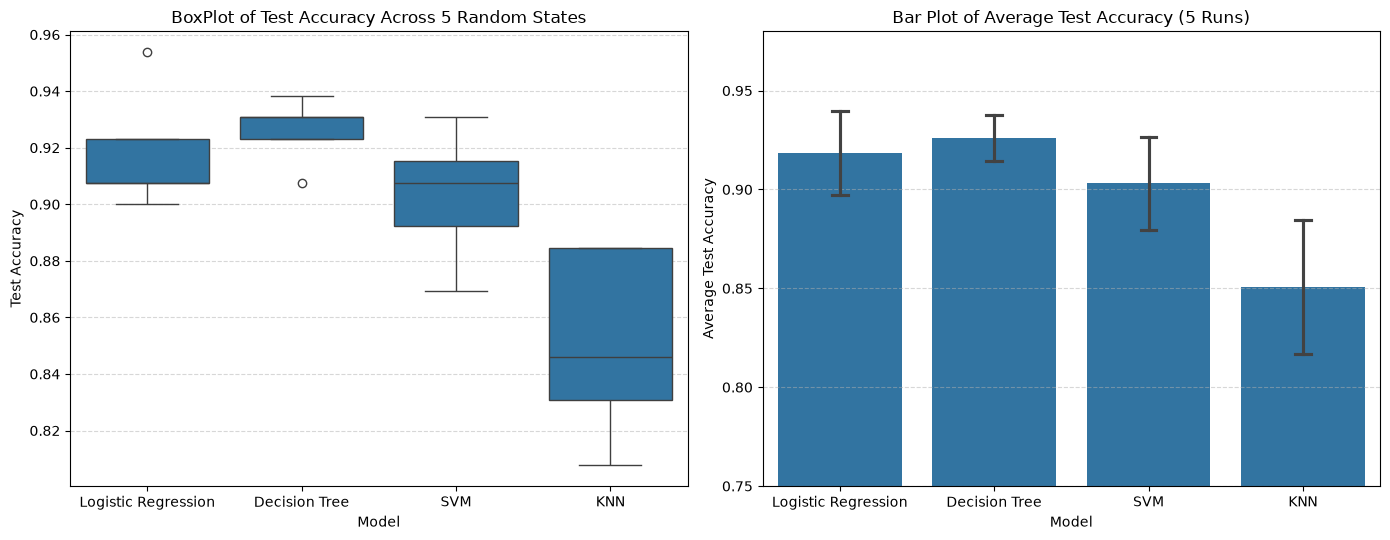

In [48]:
# 8) Change the random_state in task 2.1 and re-calculate all the previous steps. Are your conclusions about
# the best model the same? Make conclusions averaging the performance results for to five different
# random states. Construct the BoxPlots for each ML method and for each of the performance metrics,
# corresponding to the five different runs. Construct the Bar Plots for each ML method and for each of
# the performance metrics with average performance results. Describe and interpret the results.

# 8) Re-calculate previous steps across 5 different random_state values
random_states = [5, 15, 25, 35, 42]
run_records = []

for rs in random_states:
    # Split and scale data for the current random_state
    X_tr, X_te, Y_tr, Y_te = train_test_split(
        X_encoded, Y_encoded, test_size=0.2, random_state=rs
    )
    scaler = MinMaxScaler()
    X_tr_sc = scaler.fit_transform(X_tr)
    X_te_sc = scaler.transform(X_te)
    
    base_models = {
        'Logistic Regression': LogisticRegression(max_iter=1000),
        'Decision Tree': DecisionTreeClassifier(random_state=rs),
        'SVM': SVC(),
        'KNN': KNeighborsClassifier()
    }
    
    # Tune hyperparameters and record test accuracy for each model
    for name, model in base_models.items():
        grid = GridSearchCV(estimator=model, param_grid=param_grids[name], cv=5, scoring='accuracy')
        grid.fit(X_tr_sc, Y_tr)
        best_m = grid.best_estimator_
        
        run_records.append({
            'Random_State': rs,
            'Model': name,
            'Train_Accuracy': accuracy_score(Y_tr, best_m.predict(X_tr_sc)),
            'Test_Accuracy': accuracy_score(Y_te, best_m.predict(X_te_sc))
        })

runs_df = pd.DataFrame(run_records)
pivot_test = runs_df.pivot(index='Random_State', columns='Model', values='Test_Accuracy')
display(pivot_test)

# Display average performance summary
summary_stats = pivot_test.agg(['count', 'mean', 'median', 'min', 'max', 'std']).T
display(summary_stats)

# Construct BoxPlots and Bar Plots for the 5 runs
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
model_order = ['Logistic Regression', 'Decision Tree', 'SVM', 'KNN']

sns.boxplot(data=runs_df, x='Model', y='Test_Accuracy', order=model_order, ax=axes[0])
axes[0].set_title('BoxPlot of Test Accuracy Across 5 Random States')
axes[0].set_ylabel('Test Accuracy')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

sns.barplot(data=runs_df, x='Model', y='Test_Accuracy', order=model_order, errorbar='sd', capsize=0.1, ax=axes[1])
axes[1].set_title('Bar Plot of Average Test Accuracy (5 Runs)')
axes[1].set_ylabel('Average Test Accuracy')
axes[1].set_ylim(0.75, 0.98)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


In [ ]:
# Changing the random seed shifts the winning model: although SVM ranked first on the single 
# split in the earlier step, averaging across multiple random states reveals that the tuned 
# Decision Tree achieves the highest mean test accuracy and the lowest variance. Logistic Regression 
# ranks a close second and reaches the highest individual run score, SVM places third due to a dip on 
# one split, and KNN consistently trails with the lowest average accuracy and widest spread.